VERSUCH 1 – INFRAROT-ENTFERNUNGSMESSER

AUFGABE 1: ERMITTLUNG DER KENNLINIE DES ABSTANDSSENSORS
Messwerte: Abstand, mittlere Spannung und Standardabweichung

Abstand: 10 cm | Mittelwert: 1.366497 V | Standardabweichung: 0.021147 V
Abstand: 13 cm | Mittelwert: 1.192166 V | Standardabweichung: 0.025921 V
Abstand: 16 cm | Mittelwert: 1.066742 V | Standardabweichung: 0.023192 V
Abstand: 19 cm | Mittelwert: 0.949003 V | Standardabweichung: 0.023902 V
Abstand: 22 cm | Mittelwert: 0.888640 V | Standardabweichung: 0.019744 V
Abstand: 25 cm | Mittelwert: 0.830158 V | Standardabweichung: 0.024687 V
Abstand: 28 cm | Mittelwert: 0.775643 V | Standardabweichung: 0.025490 V
Abstand: 31 cm | Mittelwert: 0.731762 V | Standardabweichung: 0.025974 V
Abstand: 34 cm | Mittelwert: 0.708679 V | Standardabweichung: 0.020973 V
Abstand: 37 cm | Mittelwert: 0.693562 V | Standardabweichung: 0.023091 V
Abstand: 40 cm | Mittelwert: 0.655289 V | Standardabweichung: 0.019767 V
Abstand: 43 cm | Mittelwert: 0.655220 V

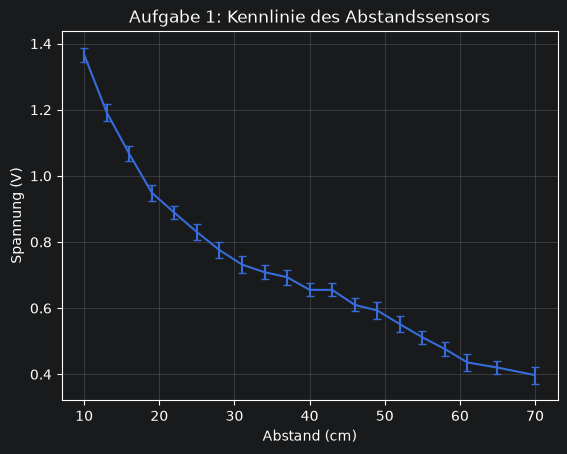


AUFGABE 2: MODELLIERUNG DER KENNLINIE DURCH LINEARE REGRESSION
Logarithmierung und Bestimmung der Ausgleichsgeraden

Steigung a: -1.600916
Achsenabschnitt b: 2.920092
Kalibrierfunktion: d(U) = exp(2.920092) * U^(-1.600916)


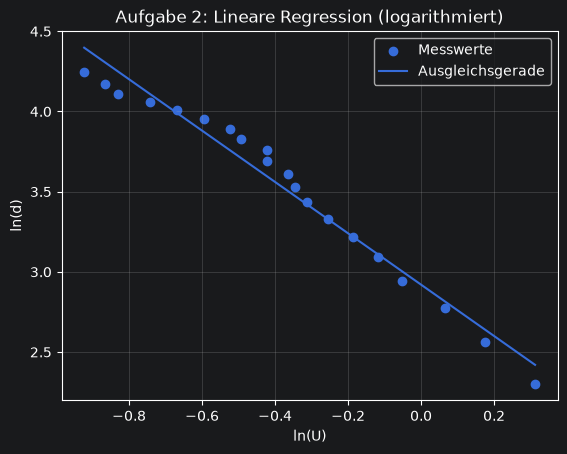


AUFGABE 2: KONTROLLE DER KALIBRIERFUNKTION
Vergleich zwischen tatsächlichem und berechnetem Abstand



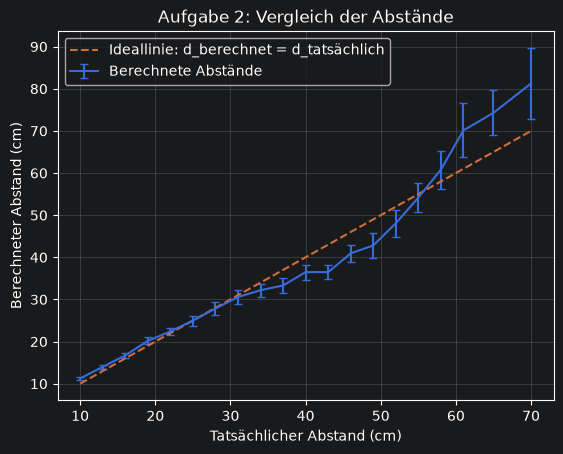


AUFGABE 3a: MESSFEHLER UND VERTRAUENSBEREICHE
Spannungsmessung am DIN-A4-Blatt (Breite und Länge)

Standardfehler der Spannung (Breite): 0.00007882 V
Standardfehler der Spannung (Länge): 0.00006771 V
Spannung Breite (68 %): 0.904456 ± 0.000079 V
Spannung Breite (95 %): 0.904456 ± 0.000154 V
Spannung Länge  (68 %): 0.697118 ± 0.000068 V
Spannung Länge  (95 %): 0.697118 ± 0.000133 V

AUFGABE 3a: ABSTANDSMESSUNG MIT FEHLERFORTPFLANZUNG
Berechnete Breite (95 %): 21.78 ± 0.01 cm
Berechnete Länge  (95 %): 33.04 ± 0.01 cm

AUFGABE 3b: FLÄCHENMESSUNG EINES DIN-A4-BLATTES
Gemessene Breite: 21.78 cm
Gemessene Länge: 33.04 cm
Gemessene Fläche: 719.50 cm²
Referenzfläche (DIN A4): 623.70 cm²
Relative Abweichung: 15.36 %
Fläche mit fortgepflanzten 95-%-Intervallen: (719.50 ± 0.29) cm²
Fläche mit fortgepflanzten Standardabweichungen: (719.50 ± 46.37) cm²

Hinweis: Die Fehlerangaben berücksichtigen nicht alle systematischen Fehler.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

def mean_std(num, txt="cm"):
    # Dezimalkomma in Dezimalpunkt umwandeln
    def convertor(str):
        return float(str.replace(",", "."))
    # Messdaten aus der CSV-Datei einlesen
    data = np.genfromtxt(f"data/{num}{txt}.csv",
                         delimiter=";",
                         converters={0: convertor, 1: convertor},
                         skip_header=2
                         )
    my_arr = data[1000::, 1]
    mittelwert = np.mean(my_arr)
    standartabweichung = np.std(my_arr, ddof=1)
    N = len(my_arr)
    standartfehler = standartabweichung / np.sqrt(N)
    return mittelwert, standartabweichung, standartfehler

print("=" * 68)
print("VERSUCH 1 – INFRAROT-ENTFERNUNGSMESSER")
print("=" * 68)
print("\nAUFGABE 1: ERMITTLUNG DER KENNLINIE DES ABSTANDSSENSORS")
print("Messwerte: Abstand, mittlere Spannung und Standardabweichung\n")

counter = 10
arr_mitt = []
arr_std = []
arr_abs = []

# Alle Messungen auswerten und in den Arrays speichern
while True:
    mitt, std, _ = mean_std(counter)
    # Messwerte in den Arrays speichern
    arr_mitt.append(mitt)
    arr_std.append(std)
    arr_abs.append(counter)

    print(f"Abstand: {counter:>2} cm | Mittelwert: {mitt:.6f} V | Standardabweichung: {std:.6f} V")
    if counter == 61:
        counter = 65
        continue
    elif counter == 65:
        counter = 70
        continue
    elif counter == 70:
        break
    else:
        counter += 3

# Aufgabe 1: Kennlinie mit Fehlerbalken
plt.errorbar(arr_abs, arr_mitt, arr_std,
             capsize=3
             )
plt.xlabel("Abstand (cm)")
plt.ylabel("Spannung (V)")
plt.title("Aufgabe 1: Kennlinie des Abstandssensors")
plt.grid(True, alpha=0.3)
plt.show()

print("\nAUFGABE 2: MODELLIERUNG DER KENNLINIE DURCH LINEARE REGRESSION")
print("Logarithmierung und Bestimmung der Ausgleichsgeraden\n")

arr_log_mitt = np.log(arr_mitt)
arr_log_abs = np.log(arr_abs)

# Steigung a und Achsenabschnitt b der Ausgleichsgeraden
a, b = np.polyfit(arr_log_mitt, arr_log_abs, deg=1)
y = a * arr_log_mitt + b
print(f"Steigung a: {a:.6f}")
print(f"Achsenabschnitt b: {b:.6f}")
print(f"Kalibrierfunktion: d(U) = exp({b:.6f}) * U^({a:.6f})")

# Aufgabe 2: Logarithmierte Messwerte und lineare Regression
plt.figure()
plt.scatter(arr_log_mitt, arr_log_abs, label="Messwerte")
plt.plot(arr_log_mitt, y, label="Ausgleichsgerade")
plt.xlabel("ln(U)")
plt.ylabel("ln(d)")
plt.title("Aufgabe 2: Lineare Regression (logarithmiert)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Umrechnung der Spannung in die Entfernung mit der Kalibrierfunktion
def distance(U):
    d = np.exp(b) * (U ** a)
    return d

# Fehlerfortpflanzung von der Spannung auf die Entfernung
def distance_error(U, sigma_U):
    d = abs(a * np.exp(b) * U ** (a - 1)) * sigma_U
    return d

print("\nAUFGABE 2: KONTROLLE DER KALIBRIERFUNKTION")
print("Vergleich zwischen tatsächlichem und berechnetem Abstand\n")

abs_calc = distance(arr_mitt)
abs_err = distance_error(arr_mitt, arr_std)

plt.figure()
plt.errorbar(arr_abs, abs_calc, abs_err, capsize=3, label="Berechnete Abstände")
plt.xlabel("Tatsächlicher Abstand (cm)")
plt.ylabel("Berechneter Abstand (cm)")
plt.plot(arr_abs, arr_abs, "--", label="Ideallinie: d_berechnet = d_tatsächlich")
plt.title("Aufgabe 2: Vergleich der Abstände")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("\nAUFGABE 3a: MESSFEHLER UND VERTRAUENSBEREICHE")
print("Spannungsmessung am DIN-A4-Blatt (Breite und Länge)\n")

a4_br_mitt, a4_br_std, a4_br_se = mean_std("A4_breite", txt="")
a4_lg_mitt, a4_lg_std, a4_lg_se = mean_std("A4_laenge", txt="")

print(f"Standardfehler der Spannung (Breite): {a4_br_se:.8f} V")
print(f"Standardfehler der Spannung (Länge): {a4_lg_se:.8f} V")

br_68 = a4_br_se
br_95 = 1.96 * a4_br_se

lg_68 = a4_lg_se
lg_95 = 1.96 * a4_lg_se

print(f"Spannung Breite (68 %): {a4_br_mitt:.6f} ± {br_68:.6f} V")
print(f"Spannung Breite (95 %): {a4_br_mitt:.6f} ± {br_95:.6f} V")

print(f"Spannung Länge  (68 %): {a4_lg_mitt:.6f} ± {lg_68:.6f} V")
print(f"Spannung Länge  (95 %): {a4_lg_mitt:.6f} ± {lg_95:.6f} V")

print("\nAUFGABE 3a: ABSTANDSMESSUNG MIT FEHLERFORTPFLANZUNG")

a4_br = distance(a4_br_mitt)
a4_lg = distance(a4_lg_mitt)

br_distance_95 = distance_error(a4_br_mitt, br_95)
lg_distance_95 = distance_error(a4_lg_mitt, lg_95)

print(f"Berechnete Breite (95 %): {a4_br:.2f} ± {br_distance_95:.2f} cm")
print(f"Berechnete Länge  (95 %): {a4_lg:.2f} ± {lg_distance_95:.2f} cm")

print("\nAUFGABE 3b: FLÄCHENMESSUNG EINES DIN-A4-BLATTES")
print(f"Gemessene Breite: {a4_br:.2f} cm")
print(f"Gemessene Länge: {a4_lg:.2f} cm")

a_real = 21 * 29.7
a_gemessen = a4_br * a4_lg

prozent = abs(a_real - a_gemessen) / a_real * 100

print(f"Gemessene Fläche: {a_gemessen:.2f} cm²")
print(f"Referenzfläche (DIN A4): {a_real:.2f} cm²")
print(f"Relative Abweichung: {prozent:.2f} %")

area_error_95 = np.sqrt(
    (a4_lg * br_distance_95) ** 2
    + (a4_br * lg_distance_95) ** 2
)

print(f"Fläche mit fortgepflanzten 95-%-Intervallen: ({a_gemessen:.2f} ± {area_error_95:.2f}) cm²")

# Fehlerfortpflanzung der Fläche
a4_br_error = distance_error(a4_br_mitt, a4_br_std)
a4_lg_error = distance_error(a4_lg_mitt, a4_lg_std)

a4_area_error = np.sqrt((a4_lg * a4_br_error)** 2 + (a4_br * a4_lg_error)** 2)

print(f"Fläche mit fortgepflanzten Standardabweichungen: ({a_gemessen:.2f} ± {a4_area_error:.2f}) cm²")
print("\nHinweis: Die Fehlerangaben berücksichtigen nicht alle systematischen Fehler.")
print("=" * 68)




